# Transformasi Geometris Citra
**Nama :** (Fazafil Asrori)  
**NIM  :** (G.211.24.0080)  
**Mata Kuliah :** Computer Vision / Pengolahan Citra Digital  

**Tujuan:** membuat fungsi untuk 7 transformasi geometris citra (translasi, rotasi, scaling, shearing, refleksi, affine, dan perspektif) yang diterapkan pada 20 citra dari folder `Dataset_monarch`. Semua citra dikonversi ke grayscale terlebih dahulu.

## 1. Import Library & Konfigurasi

In [ ]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Mount Google Drive (hanya jalan di Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print("Bukan di Colab, lewati mount drive.")

# ====== KONFIGURASI (sesuaikan path folder dataset kamu) ======
FOLDER_DATASET = "/content/drive/MyDrive/Dataset_monarch"
FOLDER_OUTPUT  = "/content/hasil_transformasi"   # tempat menyimpan hasil
UKURAN_SERAGAM = (300, 300)                      # (lebar, tinggi) agar semua citra sama ukuran
JUMLAH_MINIMAL = 20

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Membaca Dataset & Konversi ke Grayscale
Semua citra dibaca dari folder dataset, dikonversi ke **grayscale**, lalu diseragamkan ukurannya (supaya seluruh citra memiliki format dan ukuran yang sama).

In [ ]:
def muat_dataset(folder, ukuran=UKURAN_SERAGAM, minimal=JUMLAH_MINIMAL):
    """Baca semua citra di folder -> grayscale -> ukuran seragam.
    Return: (list citra grayscale, list nama file)"""
    ekstensi = ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.tif", "*.tiff", "*.webp")
    daftar_path = []
    for e in ekstensi:
        daftar_path += glob.glob(os.path.join(folder, e))
        daftar_path += glob.glob(os.path.join(folder, e.upper()))
    daftar_path = sorted(set(daftar_path))

    citra_list, nama_list = [], []
    for p in daftar_path:
        bgr = cv2.imread(p)
        if bgr is None:
            print("Gagal membaca:", p)
            continue
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)           # konversi grayscale
        gray = cv2.resize(gray, ukuran, interpolation=cv2.INTER_AREA)  # seragamkan ukuran
        citra_list.append(gray)
        nama_list.append(os.path.splitext(os.path.basename(p))[0])

    assert len(citra_list) >= minimal, (
        f"Citra kurang! Ditemukan {len(citra_list)}, minimal {minimal}. Cek path: {folder}")
    print(f"Berhasil memuat {len(citra_list)} citra grayscale, ukuran {ukuran}")
    return citra_list, nama_list


dataset, nama_file = muat_dataset(FOLDER_DATASET)

Berhasil memuat 20 citra grayscale, ukuran (300, 300)


## 3. Fungsi Transformasi Geometris

### 3.1 Translasi (pergeseran)
Matriks: `[[1,0,tx],[0,1,ty]]`

In [ ]:
def translasi(citra, tx, ty):
    """Geser citra sejauh tx (horizontal) dan ty (vertikal) piksel."""
    tinggi, lebar = citra.shape[:2]
    M = np.array([[1, 0, tx],
                  [0, 1, ty]], dtype=np.float32)
    return cv2.warpAffine(citra, M, (lebar, tinggi))

### 3.2 Rotasi
Citra diputar terhadap titik pusat. Dengan `perluas=True`, kanvas diperbesar agar sudut citra tidak terpotong.

In [ ]:
def rotasi(citra, sudut, skala=1.0, perluas=True):
    """Putar citra sebesar 'sudut' derajat (positif = berlawanan arah jarum jam)."""
    tinggi, lebar = citra.shape[:2]
    pusat = (lebar / 2, tinggi / 2)
    M = cv2.getRotationMatrix2D(pusat, sudut, skala)

    if not perluas:
        return cv2.warpAffine(citra, M, (lebar, tinggi))

    # hitung ukuran kanvas baru supaya seluruh citra muat
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    lebar_baru  = int(tinggi * sin + lebar * cos)
    tinggi_baru = int(tinggi * cos + lebar * sin)
    M[0, 2] += lebar_baru / 2 - pusat[0]
    M[1, 2] += tinggi_baru / 2 - pusat[1]
    return cv2.warpAffine(citra, M, (lebar_baru, tinggi_baru))

### 3.3 Scaling (perbesaran / pengecilan)
Perbesaran memakai interpolasi `INTER_CUBIC`, pengecilan memakai `INTER_AREA`.

In [ ]:
def scaling(citra, sx, sy=None):
    """Ubah ukuran citra dengan faktor sx (horizontal) dan sy (vertikal)."""
    if sy is None:
        sy = sx
    interpolasi = cv2.INTER_CUBIC if (sx > 1 or sy > 1) else cv2.INTER_AREA
    return cv2.resize(citra, None, fx=sx, fy=sy, interpolation=interpolasi)

### 3.4 Shearing (skewing)
Matriks: `[[1,shx,0],[shy,1,0]]`. Kanvas diperlebar agar hasil tidak terpotong.

In [ ]:
def shearing(citra, shx=0.0, shy=0.0):
    """Miringkan citra. shx = shear horizontal, shy = shear vertikal."""
    tinggi, lebar = citra.shape[:2]
    lebar_baru  = int(lebar + abs(shx) * tinggi)
    tinggi_baru = int(tinggi + abs(shy) * lebar)

    # offset supaya shear bernilai negatif tidak keluar dari kanvas
    off_x = -shx * tinggi if shx < 0 else 0
    off_y = -shy * lebar  if shy < 0 else 0

    M = np.array([[1,   shx, off_x],
                  [shy, 1,   off_y]], dtype=np.float32)
    return cv2.warpAffine(citra, M, (lebar_baru, tinggi_baru))

### 3.5 Refleksi (pencerminan)
Dibuat dengan matriks refleksi, bukan `cv2.flip`.

In [ ]:
def refleksi(citra, mode="horizontal"):
    """Cerminkan citra. mode: 'horizontal', 'vertikal', atau 'keduanya'."""
    tinggi, lebar = citra.shape[:2]
    if mode == "horizontal":      # cermin kiri-kanan
        M = np.array([[-1, 0, lebar - 1],
                      [ 0, 1, 0]], dtype=np.float32)
    elif mode == "vertikal":      # cermin atas-bawah
        M = np.array([[1,  0, 0],
                      [0, -1, tinggi - 1]], dtype=np.float32)
    elif mode == "keduanya":
        M = np.array([[-1,  0, lebar - 1],
                      [ 0, -1, tinggi - 1]], dtype=np.float32)
    else:
        raise ValueError("mode harus 'horizontal', 'vertikal', atau 'keduanya'")
    return cv2.warpAffine(citra, M, (lebar, tinggi))

### 3.6 Transformasi Affine
Definisikan 3 titik asal dan 3 titik tujuan (dalam rasio terhadap ukuran citra, sehingga cocok untuk ukuran berapa pun).

In [ ]:
def transformasi_affine(citra, titik_asal=None, titik_tujuan=None):
    """Transformasi affine dari 3 pasang titik (koordinat rasio 0..1)."""
    tinggi, lebar = citra.shape[:2]
    if titik_asal is None:
        titik_asal = [[0.0, 0.0], [1.0, 0.0], [0.0, 1.0]]
    if titik_tujuan is None:
        titik_tujuan = [[0.10, 0.15], [0.90, 0.05], [0.25, 0.95]]

    skala = np.float32([lebar - 1, tinggi - 1])
    asal   = np.float32(titik_asal)   * skala
    tujuan = np.float32(titik_tujuan) * skala

    M = cv2.getAffineTransform(asal, tujuan)
    return cv2.warpAffine(citra, M, (lebar, tinggi))

### 3.7 Transformasi Proyektif (Perspective)
Menggunakan 4 pasang titik sehingga citra tampak dilihat dari sudut pandang berbeda.

In [ ]:
def transformasi_perspektif(citra, titik_asal=None, titik_tujuan=None):
    """Transformasi perspektif dari 4 pasang titik (koordinat rasio 0..1)."""
    tinggi, lebar = citra.shape[:2]
    if titik_asal is None:
        titik_asal = [[0, 0], [1, 0], [0, 1], [1, 1]]
    if titik_tujuan is None:
        titik_tujuan = [[0.15, 0.10], [0.85, 0.00], [0.00, 0.90], [1.00, 1.00]]

    skala = np.float32([lebar - 1, tinggi - 1])
    asal   = np.float32(titik_asal)   * skala
    tujuan = np.float32(titik_tujuan) * skala

    M = cv2.getPerspectiveTransform(asal, tujuan)
    return cv2.warpPerspective(citra, M, (lebar, tinggi))

## 4. Fungsi Bantu (Tampilkan & Simpan)

In [ ]:
def tampilkan_grid(daftar_citra, daftar_judul, judul_besar, kolom=5):
    """Tampilkan banyak citra dalam bentuk grid."""
    n = len(daftar_citra)
    baris = int(np.ceil(n / kolom))
    fig, axes = plt.subplots(baris, kolom, figsize=(3 * kolom, 3 * baris))
    axes = np.array(axes).reshape(-1)
    for i, ax in enumerate(axes):
        if i < n:
            ax.imshow(daftar_citra[i], cmap="gray", vmin=0, vmax=255)
            ax.set_title(daftar_judul[i], fontsize=9)
        ax.axis("off")
    fig.suptitle(judul_besar, fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.show()


def simpan_hasil(daftar_citra, daftar_nama, nama_transformasi, folder=FOLDER_OUTPUT):
    """Simpan hasil transformasi ke folder output/<nama_transformasi>/"""
    tujuan = os.path.join(folder, nama_transformasi)
    os.makedirs(tujuan, exist_ok=True)
    for citra, nama in zip(daftar_citra, daftar_nama):
        cv2.imwrite(os.path.join(tujuan, f"{nama}_{nama_transformasi}.png"), citra)
    print(f"[{nama_transformasi}] {len(daftar_citra)} hasil disimpan di: {tujuan}")


def terapkan_ke_dataset(fungsi, nama_transformasi, tampilkan=True, simpan=True, **param):
    """Terapkan satu fungsi transformasi ke seluruh citra dataset."""
    hasil = [fungsi(c, **param) for c in dataset]
    if tampilkan:
        tampilkan_grid(hasil, nama_file, f"Hasil {nama_transformasi}")
    if simpan:
        simpan_hasil(hasil, nama_file, nama_transformasi)
    return hasil

## 5. Citra Asli (Grayscale) — 20 Citra Dataset

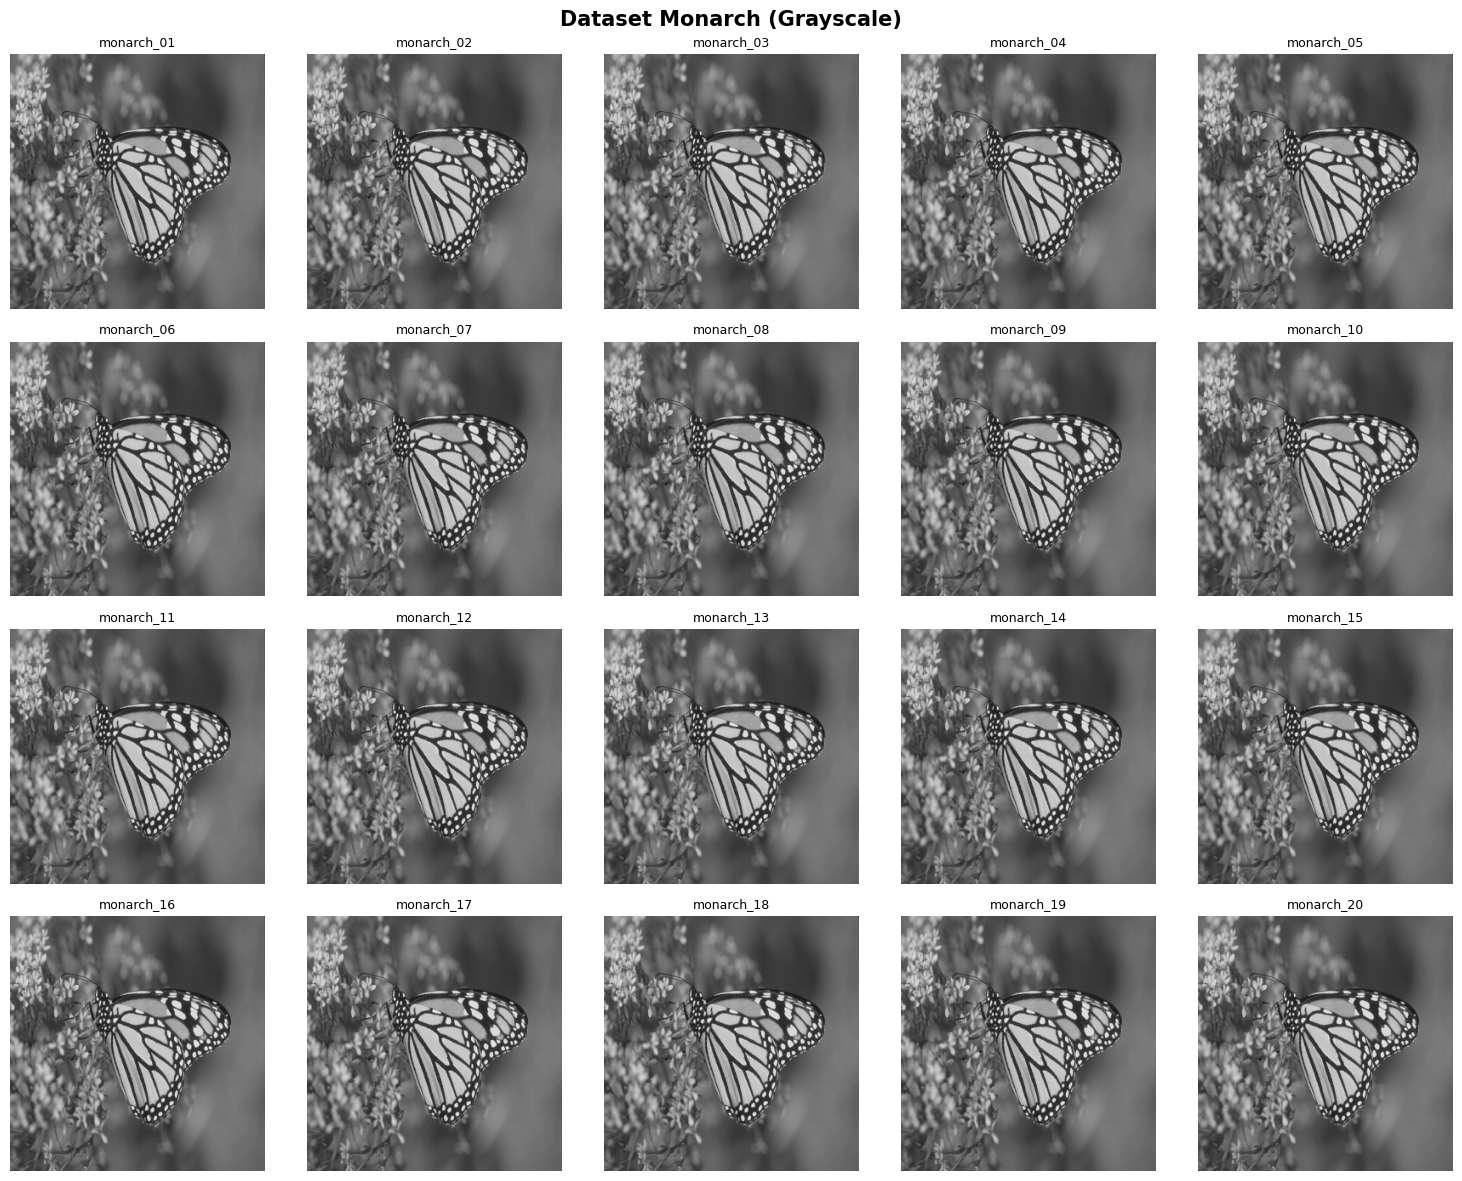

In [ ]:
tampilkan_grid(dataset, nama_file, "Dataset Monarch (Grayscale)")

## 6. Hasil Transformasi pada Seluruh Dataset

### 6.1 Translasi (tx=60, ty=40)

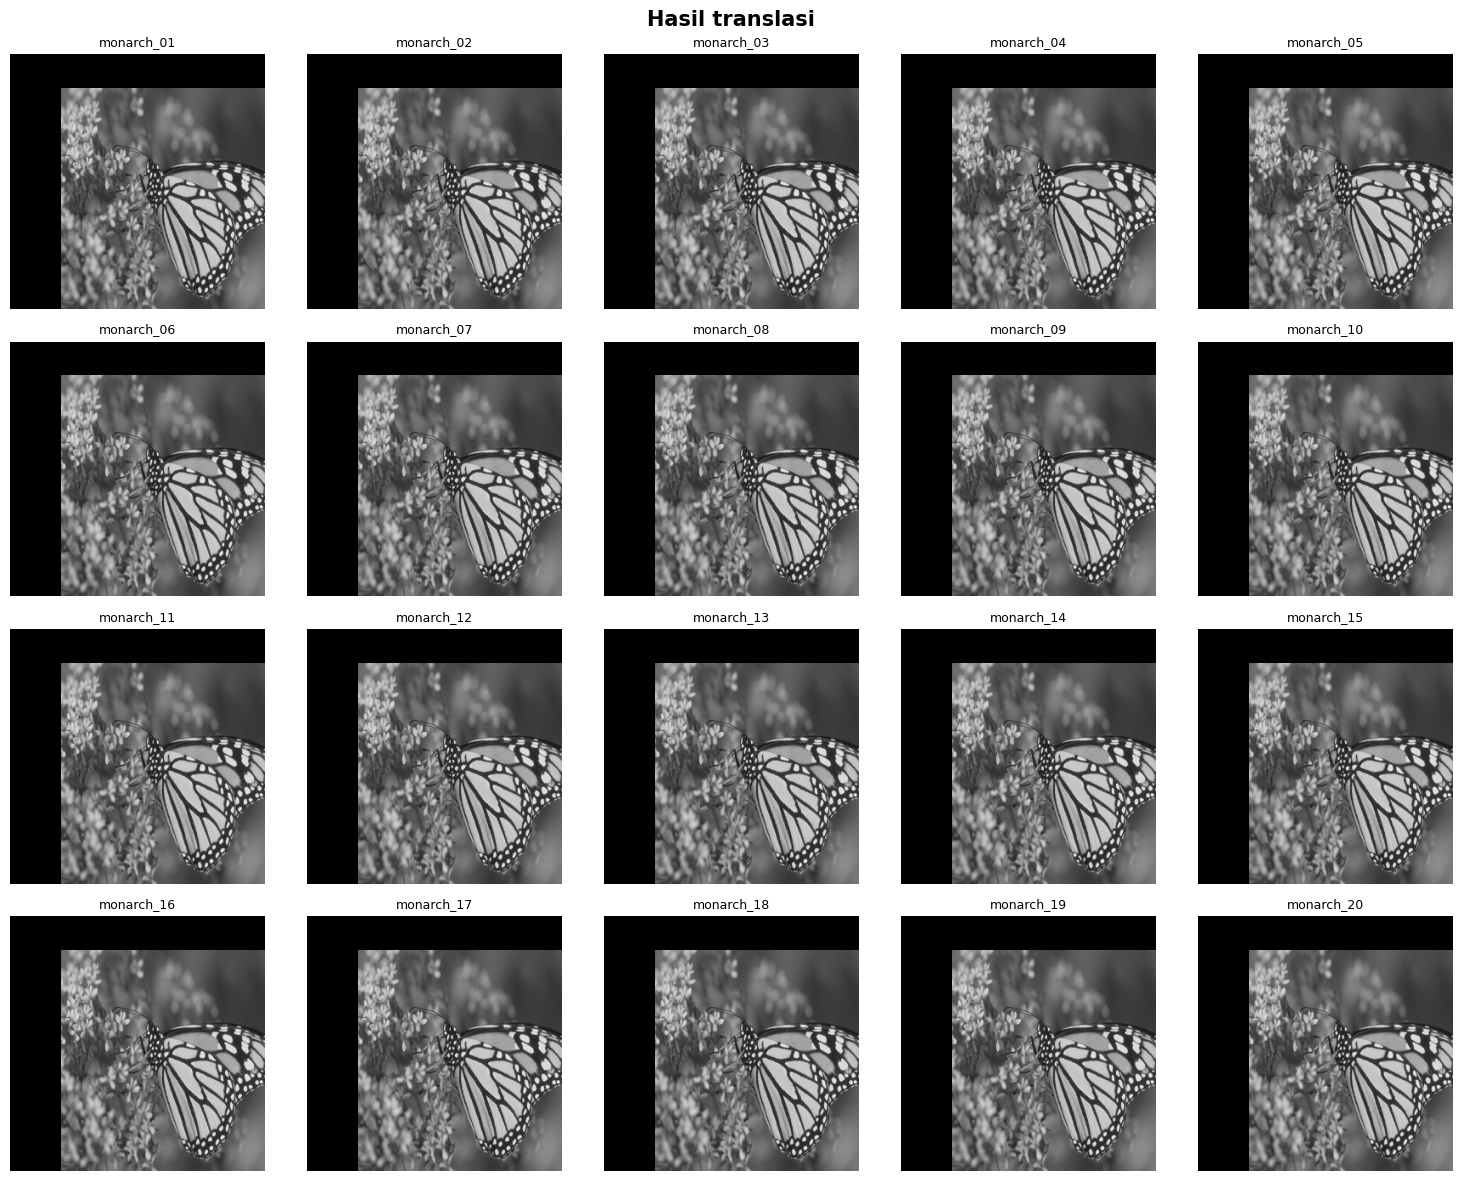

[translasi] 20 hasil disimpan di: /content/hasil_transformasi/translasi


In [ ]:
hasil_translasi = terapkan_ke_dataset(translasi, "translasi", tx=60, ty=40)

### 6.2 Rotasi (30°)

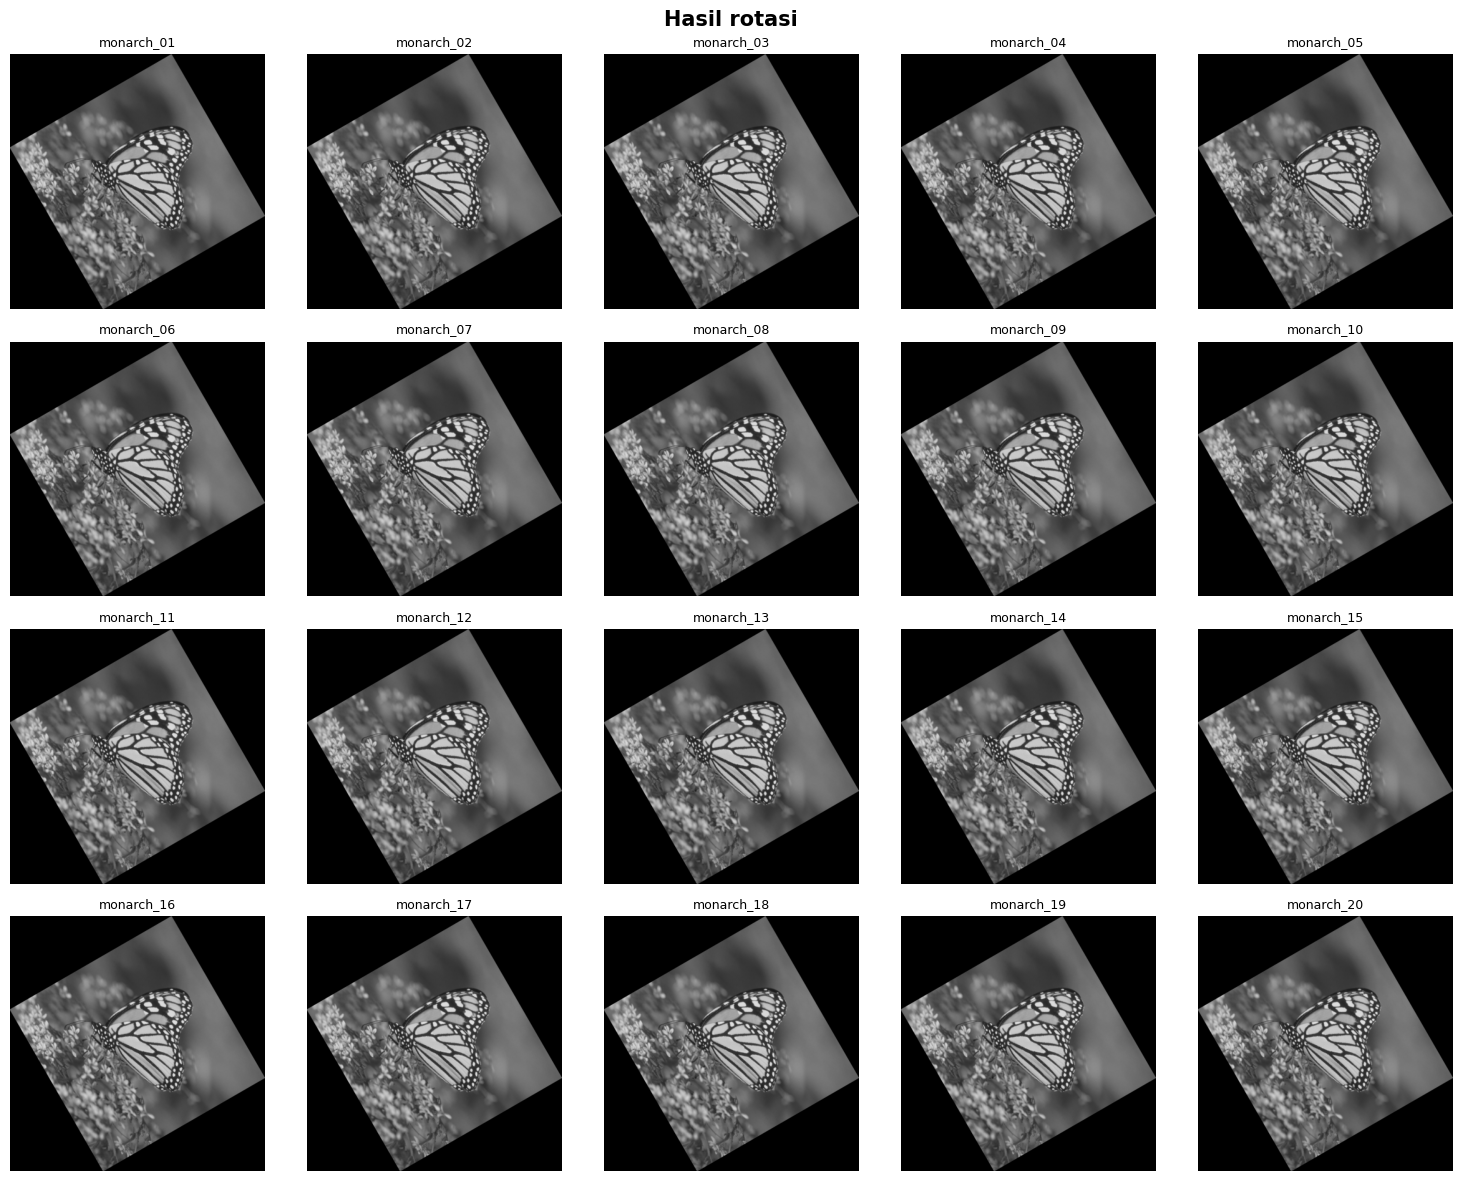

[rotasi] 20 hasil disimpan di: /content/hasil_transformasi/rotasi


In [ ]:
hasil_rotasi = terapkan_ke_dataset(rotasi, "rotasi", sudut=30)

### 6.3 Scaling (perbesar 1.5x dan perkecil 0.5x)

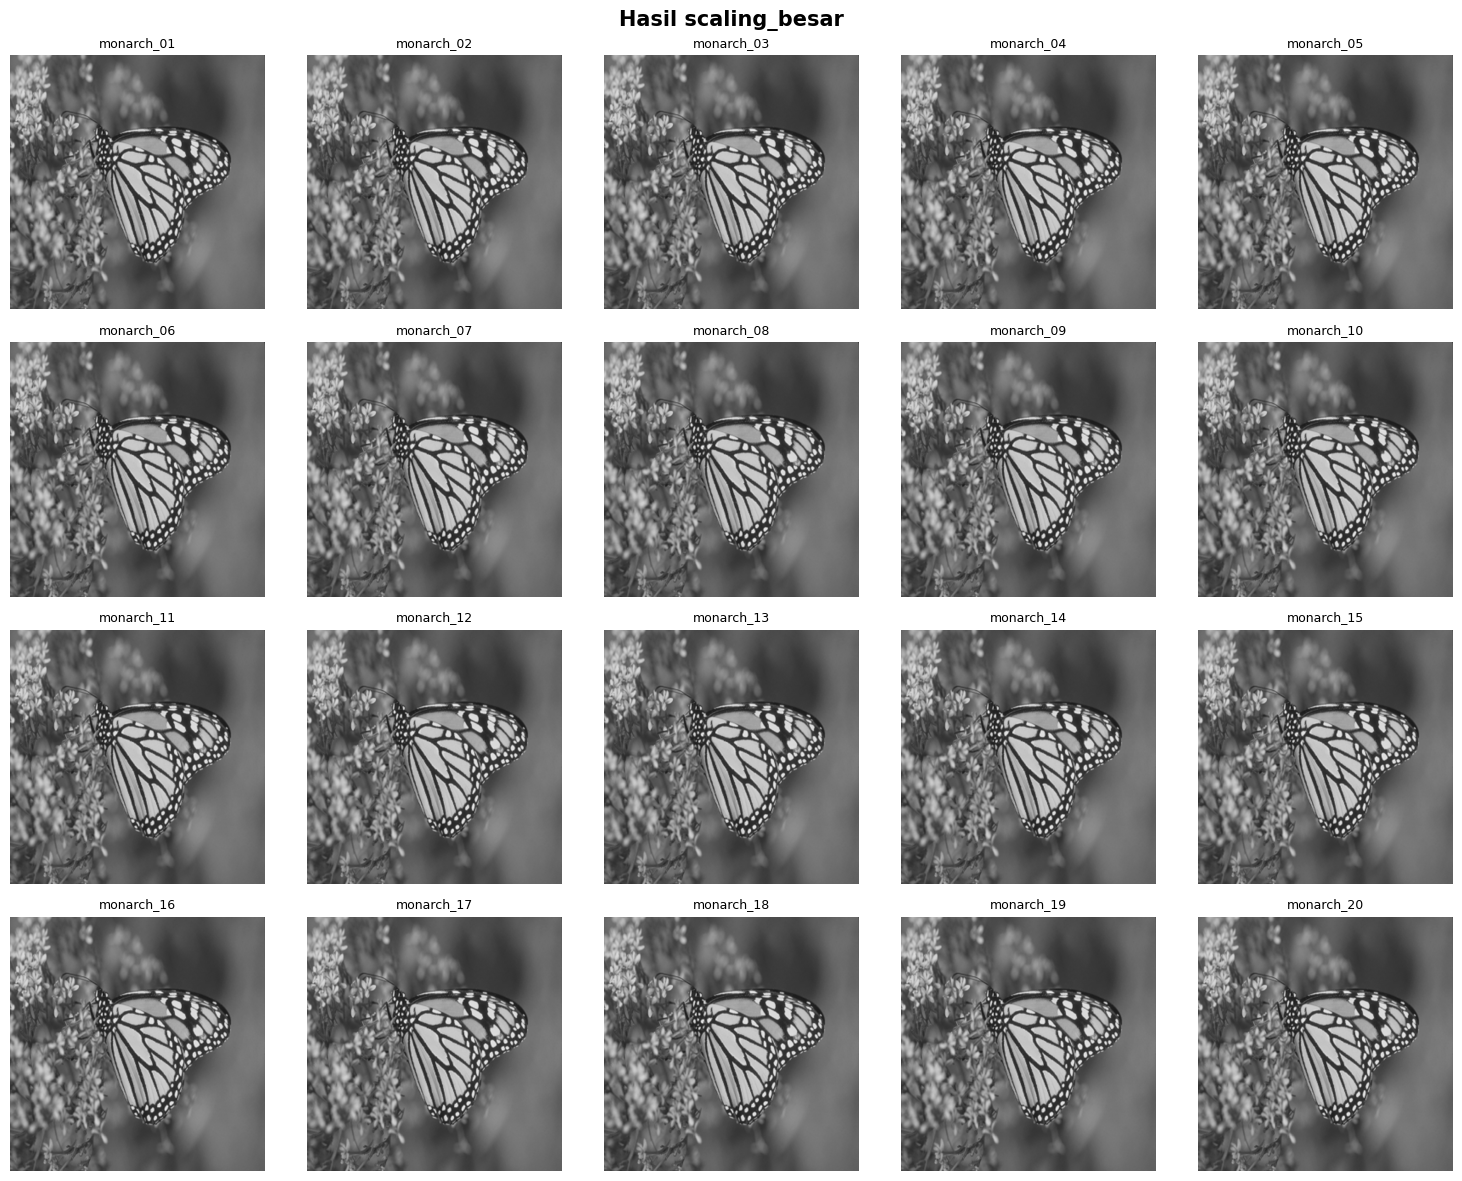

[scaling_besar] 20 hasil disimpan di: /content/hasil_transformasi/scaling_besar


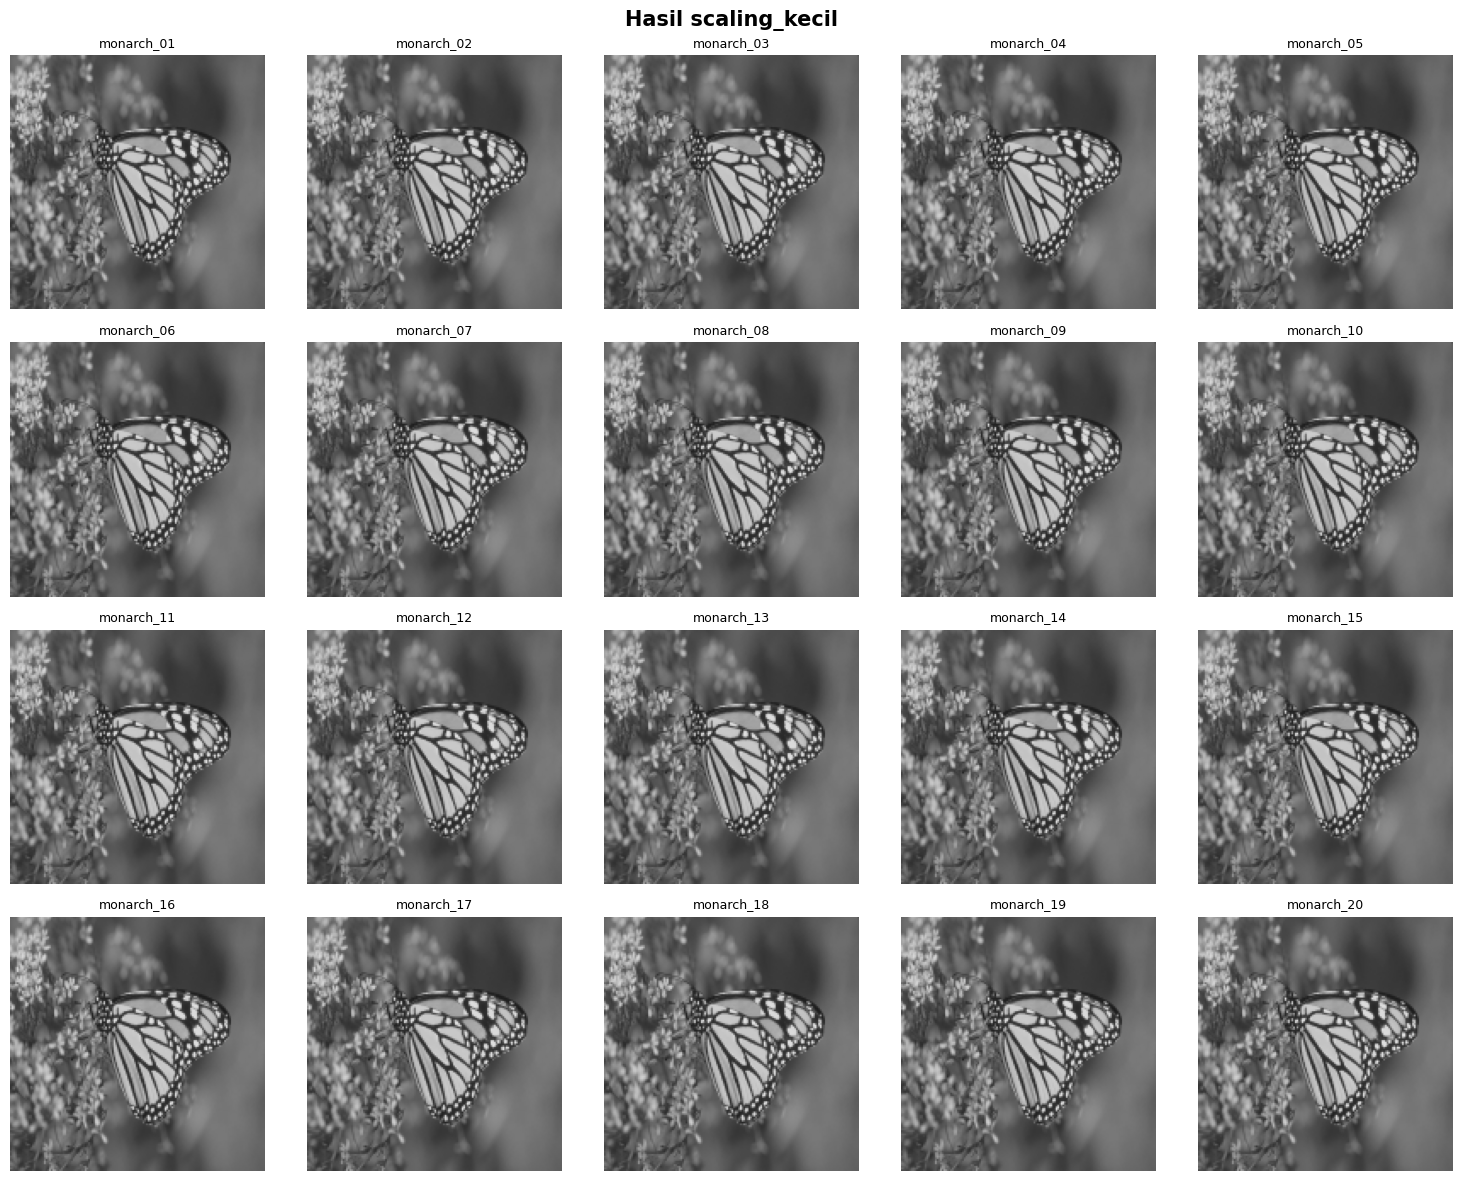

[scaling_kecil] 20 hasil disimpan di: /content/hasil_transformasi/scaling_kecil


In [ ]:
hasil_scaling_besar = terapkan_ke_dataset(scaling, "scaling_besar", sx=1.5, sy=1.5)
hasil_scaling_kecil = terapkan_ke_dataset(scaling, "scaling_kecil", sx=0.5, sy=0.5)

### 6.4 Shearing (shx=0.3, shy=0.1)

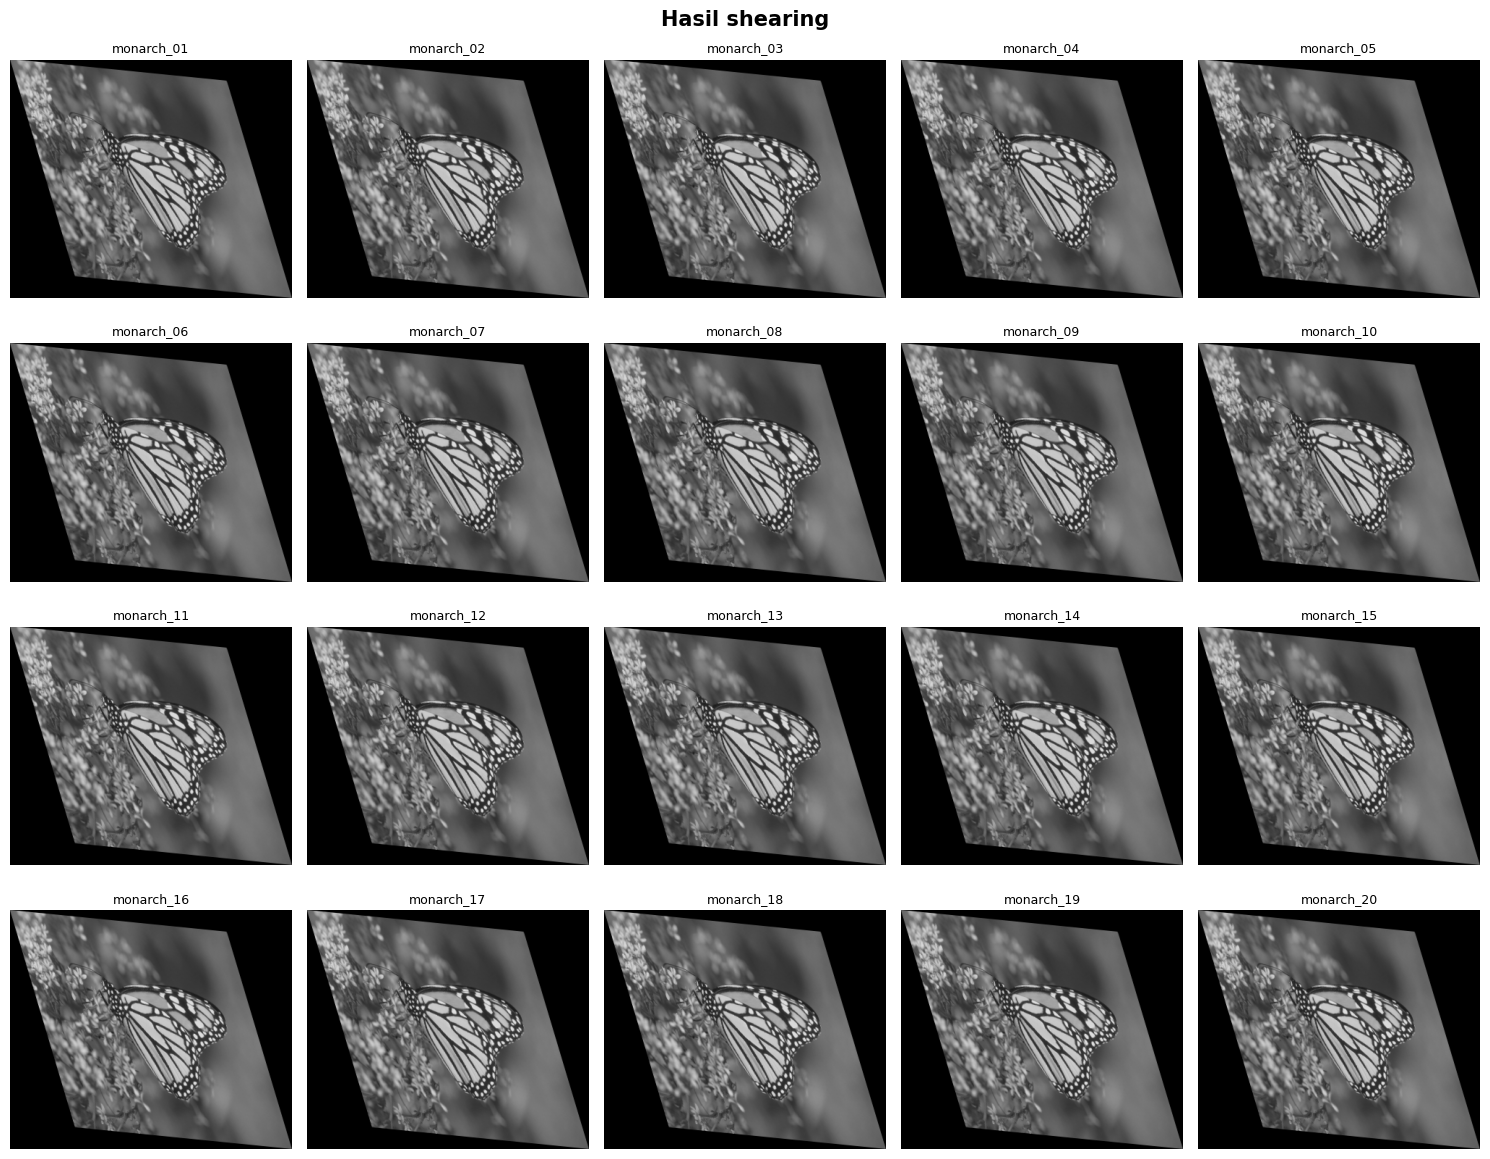

[shearing] 20 hasil disimpan di: /content/hasil_transformasi/shearing


In [ ]:
hasil_shearing = terapkan_ke_dataset(shearing, "shearing", shx=0.3, shy=0.1)

### 6.5 Refleksi (horizontal, vertikal, dan keduanya)

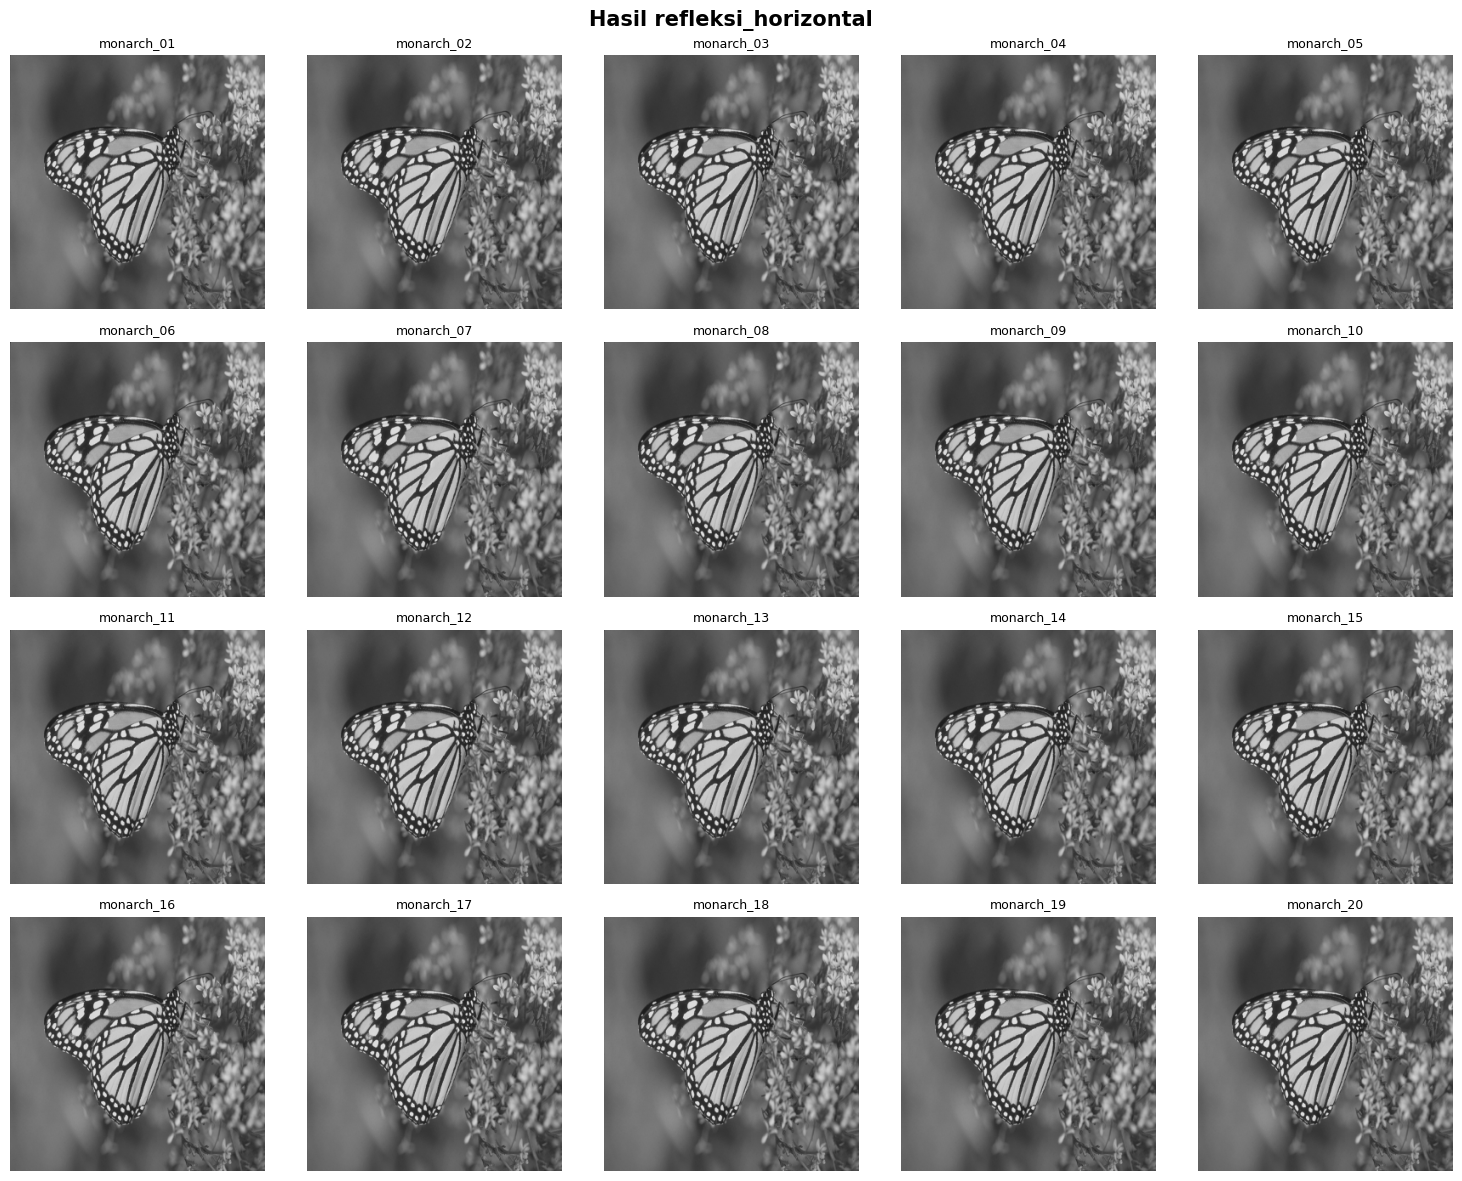

[refleksi_horizontal] 20 hasil disimpan di: /content/hasil_transformasi/refleksi_horizontal


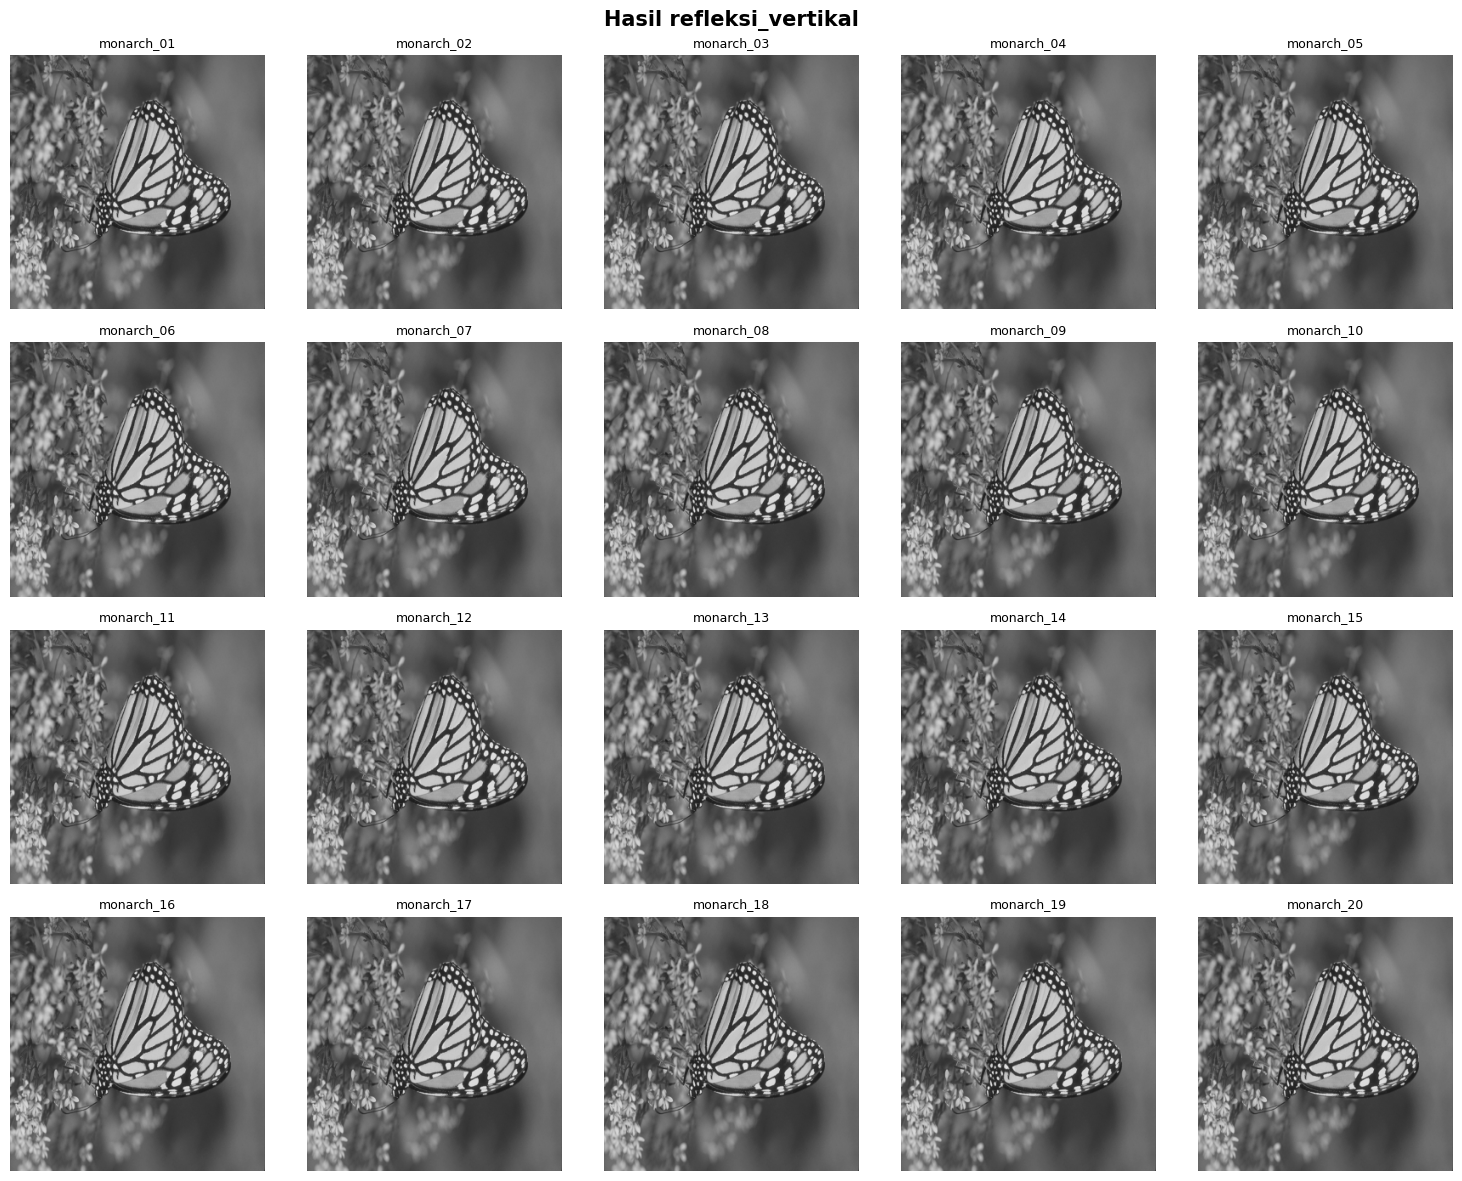

[refleksi_vertikal] 20 hasil disimpan di: /content/hasil_transformasi/refleksi_vertikal


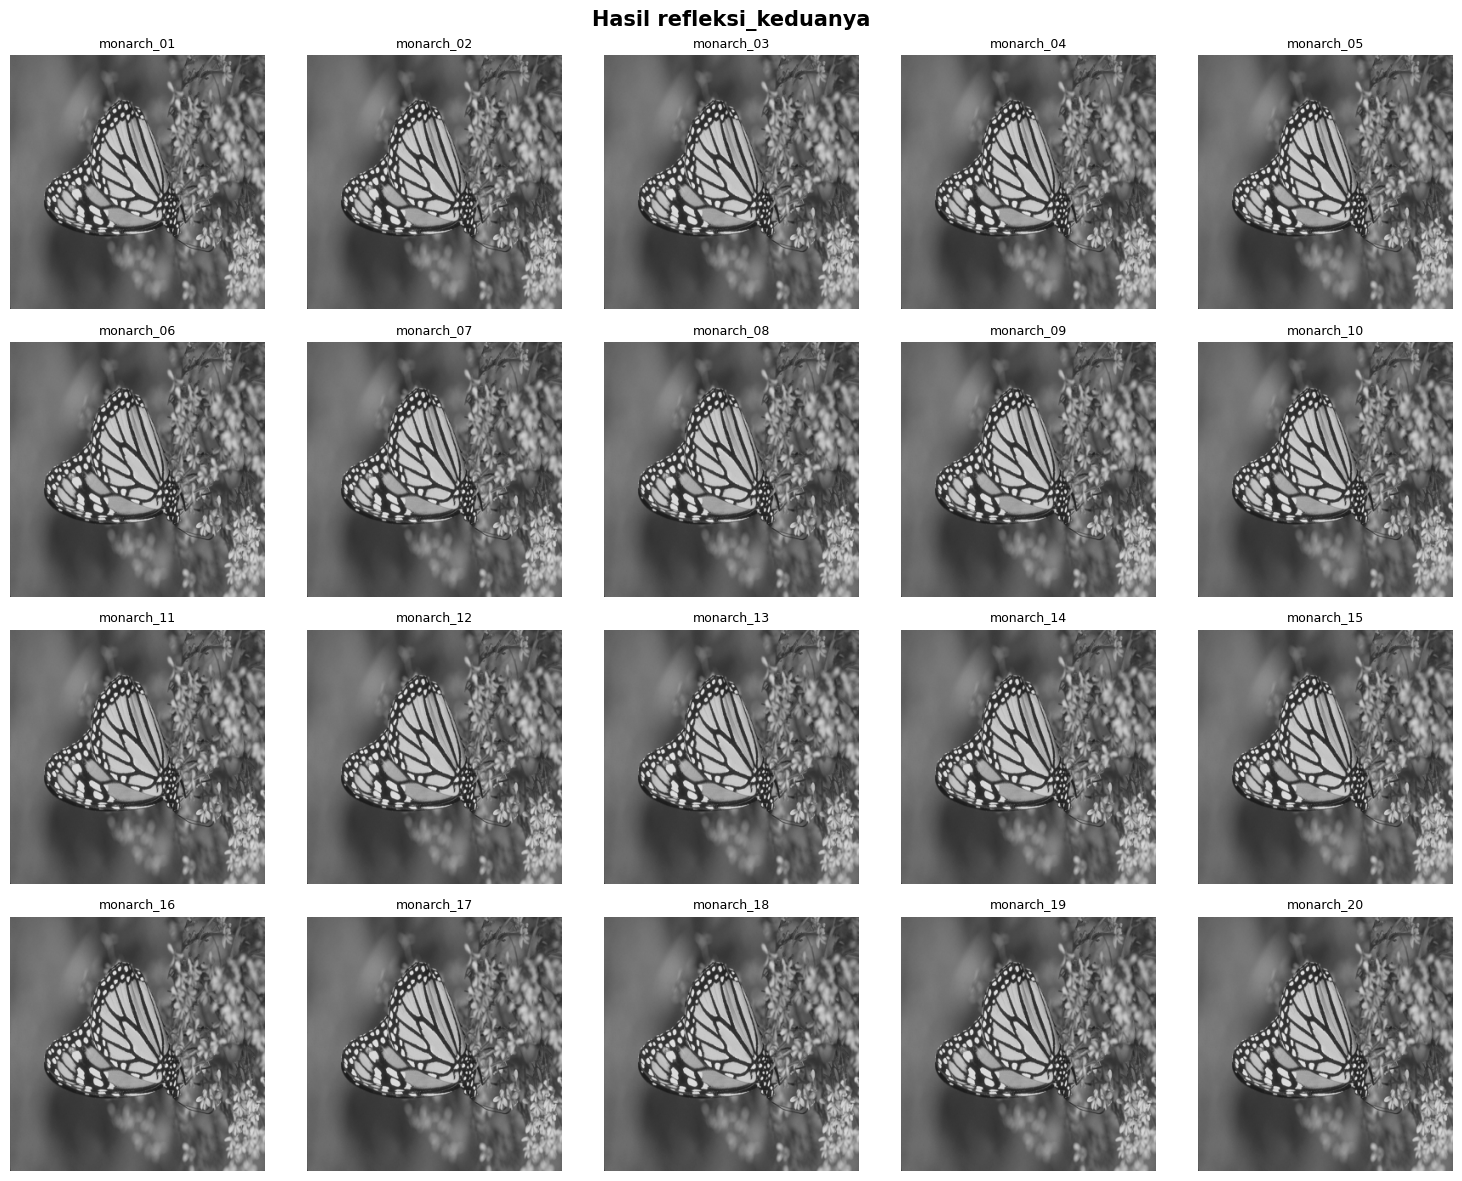

[refleksi_keduanya] 20 hasil disimpan di: /content/hasil_transformasi/refleksi_keduanya


In [ ]:
hasil_refleksi_h = terapkan_ke_dataset(refleksi, "refleksi_horizontal", mode="horizontal")
hasil_refleksi_v = terapkan_ke_dataset(refleksi, "refleksi_vertikal",   mode="vertikal")
hasil_refleksi_hv = terapkan_ke_dataset(refleksi, "refleksi_keduanya",  mode="keduanya")

### 6.6 Transformasi Affine

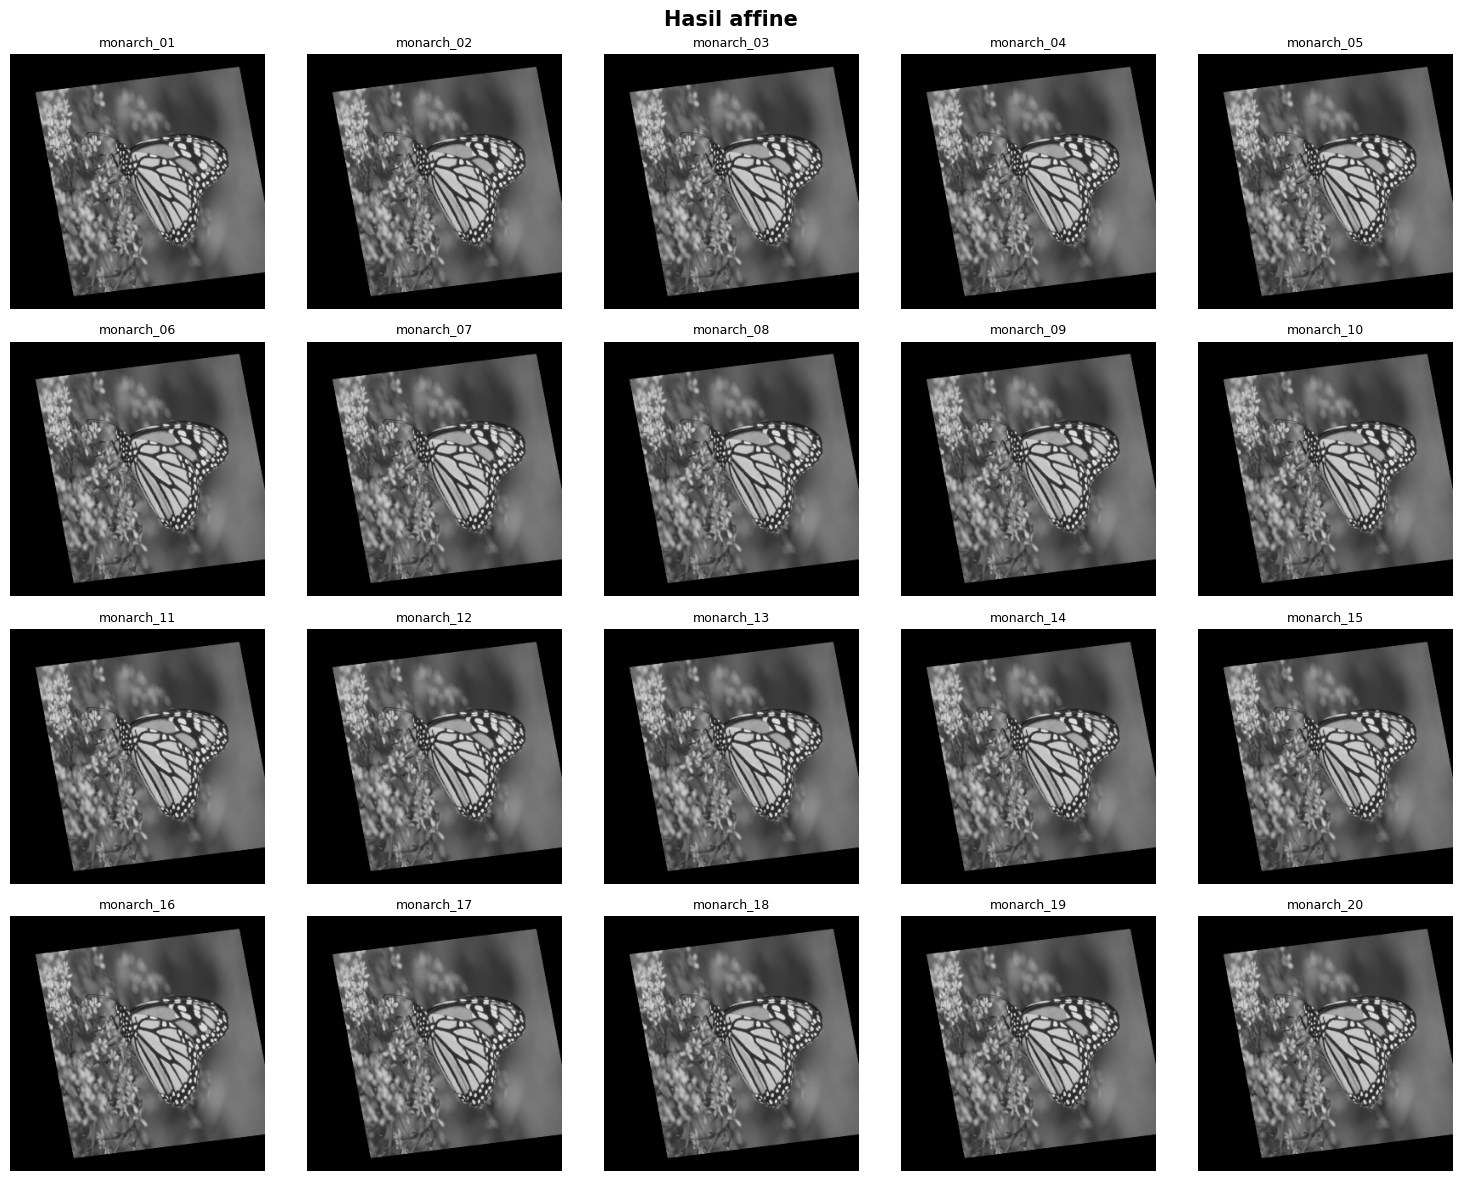

[affine] 20 hasil disimpan di: /content/hasil_transformasi/affine


In [ ]:
hasil_affine = terapkan_ke_dataset(transformasi_affine, "affine")

### 6.7 Transformasi Proyektif (Perspective)

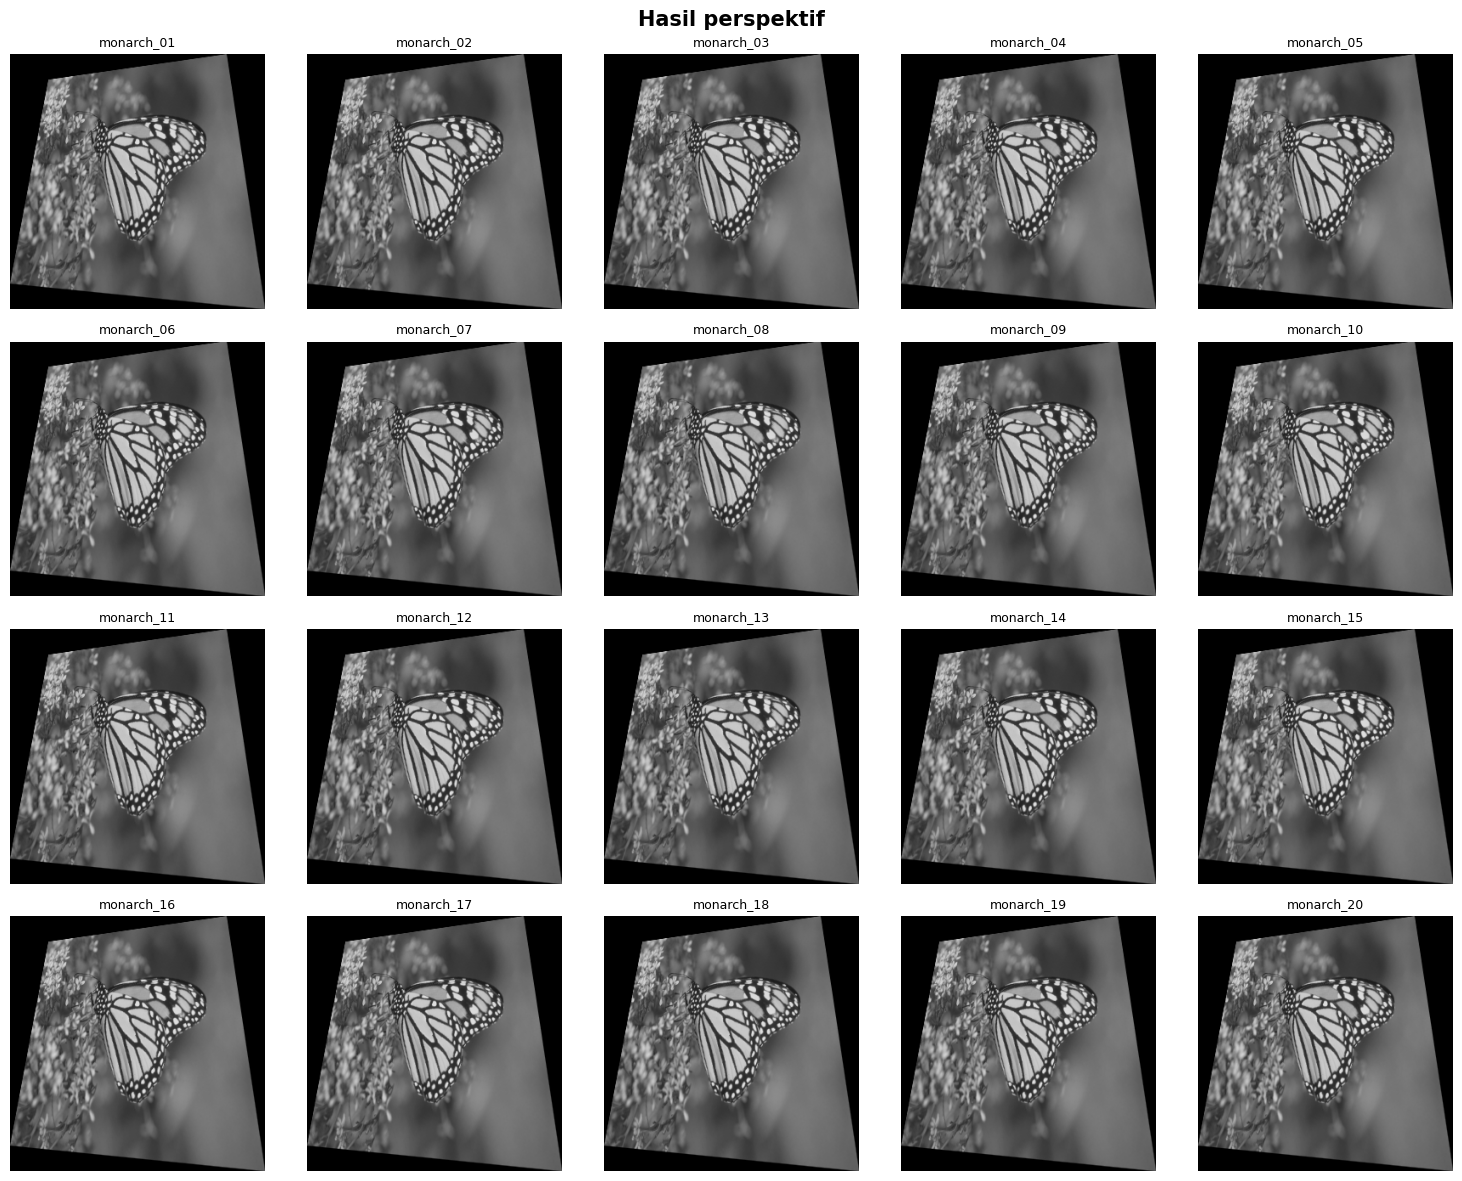

[perspektif] 20 hasil disimpan di: /content/hasil_transformasi/perspektif


In [ ]:
hasil_perspektif = terapkan_ke_dataset(transformasi_perspektif, "perspektif")

## 7. Perbandingan Semua Transformasi pada Satu Citra

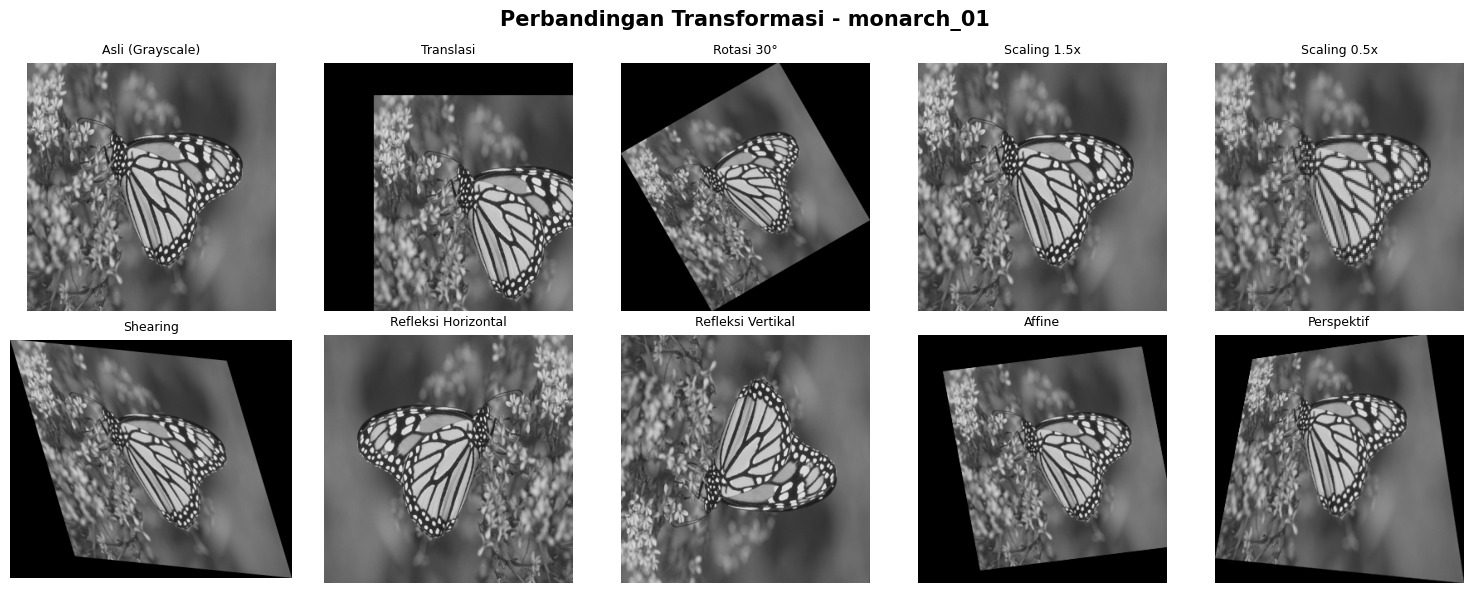

In [ ]:
idx = 0   # ganti angka ini untuk memilih citra lain (0 - 19)
c = dataset[idx]

semua = [
    ("Asli (Grayscale)", c),
    ("Translasi",        translasi(c, 60, 40)),
    ("Rotasi 30°",       rotasi(c, 30)),
    ("Scaling 1.5x",     scaling(c, 1.5)),
    ("Scaling 0.5x",     scaling(c, 0.5)),
    ("Shearing",         shearing(c, 0.3, 0.1)),
    ("Refleksi Horizontal", refleksi(c, "horizontal")),
    ("Refleksi Vertikal",   refleksi(c, "vertikal")),
    ("Affine",           transformasi_affine(c)),
    ("Perspektif",       transformasi_perspektif(c)),
]
tampilkan_grid([x[1] for x in semua], [x[0] for x in semua],
               f"Perbandingan Transformasi - {nama_file[idx]}", kolom=5)

## 8. Kesimpulan
- **Translasi** menggeser posisi citra; area kosong diisi hitam.
- **Rotasi** memutar citra terhadap pusat; kanvas diperluas agar tidak terpotong.
- **Scaling** mengubah ukuran citra (interpolasi cubic untuk memperbesar, area untuk memperkecil).
- **Shearing** memiringkan citra searah sumbu x/y.
- **Refleksi** mencerminkan citra secara horizontal, vertikal, atau keduanya.
- **Affine** mempertahankan kesejajaran garis (3 titik acuan).
- **Perspektif** mengubah sudut pandang sehingga garis sejajar bisa tidak sejajar (4 titik acuan).